## Tutorium: PyPSA 1 - Network und Basiskomponenten

### 1.1 Network

Das Basisobjekt von PyPSA ist das network. Das network beinhaltet alle anderen Objekte, es dient also als Container für diese. Über das network werden Funktionen aufgerufen, die alle Objekte eines Netzwerkes betreffen, darunter:
- `set_snapshots()`: Festlegung der Perioden.
- `optimize()`: Erstellt aus dem network ein Linopy-Modell und führt die Optimierung durch.

In [1]:
import pypsa
import pandas as pd

network = pypsa.Network() # Ein Objekt der Klasse Network() wird erstellt. Als Name wird 'network' gewählt.

df_data = pd.read_csv('data_PyPSA_T1.csv')

network.set_snapshots(df_data.index)

df_data

E0000 00:00:1793549279.629153    9153 instrument.cc:563] Metric with name 'grpc.resource_quota.calls_dropped' registered more than once. Ignoring later registration.
E0000 00:00:1793549279.629204    9153 instrument.cc:563] Metric with name 'grpc.resource_quota.calls_rejected' registered more than once. Ignoring later registration.
E0000 00:00:1793549279.629207    9153 instrument.cc:563] Metric with name 'grpc.resource_quota.connections_dropped' registered more than once. Ignoring later registration.
E0000 00:00:1793549279.629211    9153 instrument.cc:563] Metric with name 'grpc.resource_quota.instantaneous_memory_pressure' registered more than once. Ignoring later registration.
E0000 00:00:1793549279.629213    9153 instrument.cc:563] Metric with name 'grpc.resource_quota.memory_pressure_control_value' registered more than once. Ignoring later registration.
/opt/conda/lib/python3.13/site-packages/pypsa/network/io.py:2082: FutureWarning: pandas infers the `str` dtype for string data sinc

,elektrische Last,PV Erzeugung,Wärmelast
0,0.433394,0.0,3.075631
1,1.030247,0.0,3.036577
2,0.542903,0.0,3.008365
3,0.584443,0.0,2.995391
4,0.524573,0.0,2.987550
...,...,...,...
8779,0.541104,0.0,3.538371
8780,0.851679,0.0,3.386830
8781,0.424584,0.0,3.235733
8782,0.641945,0.0,3.133662


### 1.2 Basiskomponenten

Folgende Basiskomponenten existieren in PyPSA:

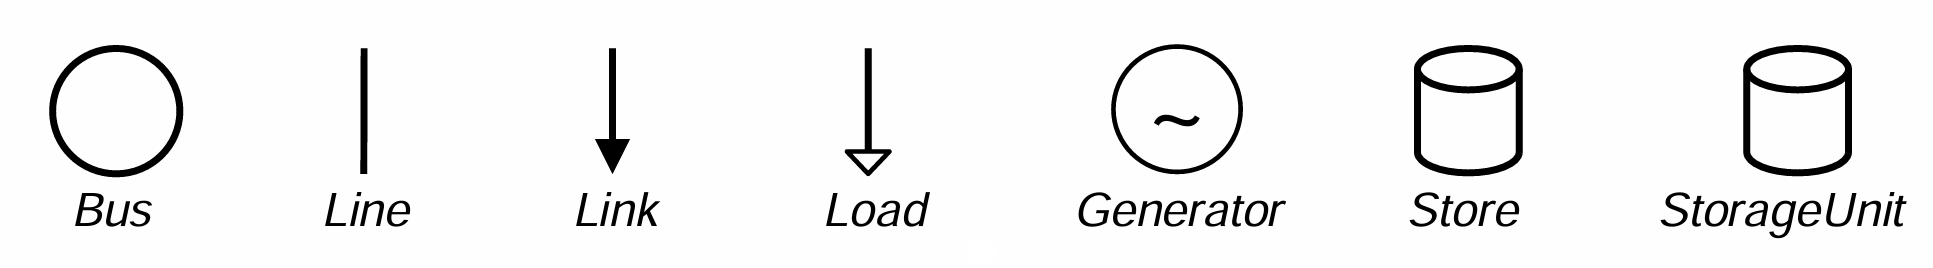

| Komponente| Beschreibung |
| --- | --- |
| [Bus](https://docs.pypsa.org/latest/user-guide/components/buses/) | Knotenpunkt, an dem andere Komponenten anknüpfen |
| [Load](https://docs.pypsa.org/latest/user-guide/components/loads/) | Energieverbraucher/Last |
| [Generator](https://docs.pypsa.org/latest/user-guide/components/generators/) | Energiegenerator/Kraftwerk |
| [Line](https://docs.pypsa.org/latest/user-guide/components/lines/) | (Strom-)Leitung/Unkontrollierte Busverbindung |
| [Link](https://docs.pypsa.org/latest/user-guide/components/links/) | Verbindung/Kontrollierte Busverbindung |
| [Store](https://docs.pypsa.org/latest/user-guide/components/stores/) | Speicher, bei dem die Nennenergie festgelegt wird |
| [StorageUnit](https://docs.pypsa.org/latest/user-guide/components/storage-units/) | Speicher, bei dem die Nennleistung festgelegt wird |



#### 1.2.1 Bus
Die Bus Komponente ist ein Knotenpunkt, an dem andere Komponenten anküpfen. Die Energieform an einem Bus muss konsistent sein.<br>
Das einzig notwendige Attribut bei einem Bus ist `name`, vorerst ist dies auch das einzige Attribut, das wir selbst festlegen.

`network.add('Bus', name='bus_name')`

---

Fügen Sie dem oben definerten Network zwei Busse hinzu: `electric` und `thermal`

In [2]:
network.add('Bus', name='electric')
network.add('Bus', name='thermal')

#### 1.2.2 Load
Durch die Load Komponente kann ein Energieverbraucher definiert werden. Festgelegt werden muss dabei der Name des Verbrauchers, der Bus, an dem der Verbraucher angebunden ist und die Leistung, die der Verbraucher benötigt.<br>
Die Leistung wird mit dem Attribut `p_set` festgelegt. Dabei gibt es zwei Möglichkeiten:
1. Eine einzelne Zahl wird übergeben (z.B. `p_set=3`). Dadurch ist die Last des Verbrauchers über alle Snapshots konstant.
2. Eine Serie an Zahlen wird übergeben (z.B. `p_set=[3,2,4]`). Die Länge muss dabei den Snapshots entsprechen. Für jeden Snapshot wird dadurch der jeweilige Zahlenwert als Last angenommen.

`network.add('Load', name='load_name', bus='bus_name' p_set=Zahl/Zahlenserie)`

---

Fügen Sie zwei Load komponenten für als Stromverbrauch und Wärmeverbrauch des Haushalts hinzu. Diese sollen aus dem gegebenen Dataframe `df_data` entnommen werden

In [3]:
network.add('Load', name='load_el', bus='electric', carrier='load_el', p_set=df_data["elektrische Last"])
network.add('Load', name='load_th', bus='thermal', carrier='load_th', p_set=df_data["Wärmelast"])

#### 1.2.3 Generator
Die Generator Komponente wird in der Regel für Kraftwerke verwendet. Notwendige Attribute sind dabei wieder Name und Bus. Im Gegensatz zu einer Load soll in nahezu allen Optimierungsproblemen nicht festgelegt werden, welche Leistung zu welchem Snapshot generiert wird. PyPSA bestimmt selbst, welche Leistung wann optimal ist.

*In dem aus PyPSA abgeleiteten Optimierungsproblem ergibt sich aus der Leistung einer Load eine Randbedingung, zu jedem Zeitpunkt muss die Last gedeckt sein. Die Leistung eines Generators ist eine Variable, sie kann angepasst werden, um die Zielfunktion und alle Randbedingungen zu erfüllen.*

Statt die Leistung selbst festzulegen geben wir demanch Grenzen an, die eingehalten werden müssen. Diese Grenzen legen wir fest durch:
1. `p_nom` oder `p_nom_extendable`: 
    - Begrenzt die **maximale Leistung über alle Zeitschritte** (Nennleistung). 
    - Ist die Nennleistung bekannt, kann durch `p_nom` die Leistung begrenzt werden. 
    - Wenn die Nennleistung optimiert werden soll, wird festgelegt `p_nom_extendable=True`.
2. `p_min_pu` und `p_max_pu`:  
    - Begrenzt die **maximale/minimale Leistung pro Zeitschritt**. 
    - Bezieht sich auf das gewählte `p_nom` und benötigt Werte zwischen 0 und 1, deswegen pu für per unit. 
    - Im Default gilt: `p_max_pu=1` und `p_min_pu=0`.
    - Deswegen: Lastprofile für PV/Wind für 1 kW Nennleistung oft sinnvoll. 
    - Liegen nur absolute Leistungswerte pro Zeitschritt vor: Leistung/Nennleistung für Normierung. 

Damit PyPSA eine die Leistung optimieren kann, sind Kosten vonnöten. Das Attribut `marginal_cost` kann für laufende Kosten verwendet werden, in `capital_cost` werden die Investitionskosten pro Leistung (€/kW, €/MW etc.), insbersondere relevante wenn `p_nom_extendable=True`.

Die Effizienz eines Generators kann durch das Attribut `efficiency` angegeben werden. Relevant, wenn der Generator einen Energieträger in einen anderen umwandelt.<br>

`network.add('Generator', name='gen_name', bus='bus_name', p_nom/p_nom_extendable, p_min_pu/p_max_pu, marginal_cost/capital_cost, efficiency)`

---

Fügen Sie nun drei Generatoren hinzu:
- Stromanschluss des Haushalts
    - Anschlussleistung: 15 kW 
    - Stromkosten: 0.3 €/kWh
- PV-Anlage die gebaut werden soll (Größe wird optimiert)
    - Investitionskosten (Annuität): 75 €/kW a
    - Laufende kosten: 0 €/kWh
    - Einspeiseprofil aus csv
- Bestehende Gasheizung
    - Nennleistung: 4 kW
    - Effizienz: 90%
    - Laufende Kosten: 0.1 €/kWh

In [4]:
network.add('Generator', name='grid_supply', bus='electric', carrier='grid', p_nom=5, marginal_cost=0.3)
network.add('Generator', name='pv', bus='electric', carrier='pv', p_nom_extendable=True, p_max_pu=df_data["PV Erzeugung"], capital_cost=75)
network.add('Generator', name='gas', bus='thermal', carrier='gas', p_nom=4, efficiency=0.9, marginal_cost=0.1)

#### 1.2.4 Link 


Die Link Komponente wird als Verbindung zwischen zwei oder mehr Bussen verwendet. Dafür müssen mindestens zwei Busse angegeben werden, die durch den Link verbunden werden: `bus0` und `bus1`. Im default Fall gibt es eine Flussrichtung, von `bus0` zu `bus1`. Die vorgegebene Flussrichtung mach die Link Komponente gut geeignet für Komponenten, die zwischen zwei Energieformen im Modell umformen (Wärmepumpe, Heizstab, Elektrolyseur)
 



Äquivalent zum Generator soll in Optimierungsproblemen in der Regel keine Leistung vorgegeben werden, sondern von PyPSA optimiert werden. Dadurch besitzt ein Link alle vorgestellten Attribute, die auch der Generator hat.<br>

`network.add('Link', name='link_name', bus0='bus_name0', bus1='bus_name1', p_nom/p_nom_extendable, p_min_pu/p_max_pu, marginal_cost/capital_cost, efficiency)`

---

Fügen Sie nun einen Link zu, ein Heizstab, dessen Größe optimiert werden soll
- Investitionskosten (Annuität) = 10 €/kW a
- 95% Effizienz 

In [5]:
network.add('Link', name='heating_rod', bus0='electric', bus1='thermal', carrier='heating_rod', p_nom_extendable=True, efficiency=0.95, capital_cost=10)

#### 1.2.5 Storage Unit

Durch die StorageUnit Komponente lassen sich Speicher abbilden. Äquivalent zu Generator und Link, wird die Nennleistung des Speichers festgelegt oder als Optimierungsgröße freigegeben.

Die Speicherkapazität wird die Entladedauer definiert. Das entsprechende Attribut ist dabei ``max_hours`. Es gilt:
- `e_nom = p_nom * max_hours`
- Default: `max_hours=1` heißt: `e_nom = p_nom`   

Statt einem Attribut `efficiency` gibt es für die StorageUnit drei Attribute für die Effizienz:
- `efficiency_store` als Effizienz beim Aufladen
- `efficiency_dispatch` als Effizienz bei Entladen
- `standing_loss` als Standverluste pro Snapshot
<br>

`network.add('StorageUnit', name='storageunit_name', bus='bus_name',  p_nom/p_nom_extendable, p_min_pu/p_max_pu, marginal_cost/capital_cost, efficiency_store/efficiency_dispatch, standing_loss)`

---

Fügen Sie einen Batteriespeicher hinzu, dessen Größe optimiert werden soll
- Investitionskosten (Annuität): 100 €/kW a
- Entladedauer: 2 h 
- Effizienz Aufladen: 99%
- Effizienz Entladen: 98%
- Keine Standverluste

In [6]:
network.add('StorageUnit', name='battery', bus='electric', carrier='battery', p_nom_extendable=True, max_hours=2, efficiency_store=0.99, efficiency_dispatch=0.98, capital_cost=100)

#### 1.2.6 Store

Auch durch die Store Komponente lassen sich Speicher darstellen. Die Differenzen zu einer StorageUnit sind:
1. Energie wird direkt definiert/optimiert, nicht die Leistung. Dadurch Attribute `e_nom` oder `e_nom_extendable`, sowie `e_min_pu` und `e_max_pu`
2. Keine Belade-/Entladeverluste, nur Standverluste möglich

Wann ist ein Store einer StorageUnit vorzuziehen:
1. Nennleistung nicht bekannt/nicht relevant für das Problem
2. Ein- und Ausspeichern hat nicht die gleiche Leistung
    - Store mit zwei Links statt Storage Unit. Die Links können unterschiedliche Nennleistungen haben, bei der StorageUnit gilt: Ladeleistung = Entladeleistung

`network.add('Store', name='store_name', bus='bus_name',  e_nom/e_nom_extendable, e_min_pu/e_max_pu, marginal_cost/capital_cost, standing_loss)`

---

Fügen Sie einen thermischen Speicher hinzu.
- Nutzbare Wärmekapazität: 10 kWh
- Standverluste: 1%/h

In [7]:
network.add('Store', name='thermal_storage', bus='thermal', carrier='thermal_storage', e_nom=10, standing_loss=0.01)

Nach dem Hinzufügen aller Komponenten kann das Netzwerk optimiert werden.

In [8]:
network.optimize(solver_name='gurobi')

/tmp/ipykernel_9153/3854944838.py:1: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  network.optimize(solver_name='gurobi')
Index(['electric', 'thermal'], dtype='object', name='name')
Index(['grid_supply', 'pv', 'gas'], dtype='object', name='name')
Index(['load_el', 'load_th'], dtype='object', name='name')
Index(['heating_rod'], dtype='object', name='name')
Index(['thermal_storage'], dtype='object', name='name')
Index(['battery'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Gurobi solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████| 10/10 [00:00<00:00, 228.49it/s]
INFO:linopy.io: Writing time: 0.31s


Set parameter ServerTimeout to value 10


INFO:gurobipy:Set parameter ServerTimeout to value 10


Set parameter TokenServer to value "139.6.183.241"


INFO:gurobipy:Set parameter TokenServer to value "139.6.183.241"


Read LP format model from file /tmp/linopy-problem-7kb4gkvy.lp


... (147 outputs left out)

INFO:gurobipy:Solved in 11579 iterations and 7.49 seconds (1.28 work units)


Optimal objective  2.232418404e+03


INFO:gurobipy:Optimal objective  2.232418404e+03
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 79059 primals, 175683 duals
Objective: 2.23e+03
Solver: gurobi
Runtime: 7.49s
Dual bound: 2.23e+03
Solver model: available
Solver message: 2

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Generator-ext-p-lower, Generator-ext-p-upper, Link-ext-p-lower, Link-ext-p-upper, Store-fix-e-lower, Store-fix-e-upper, StorageUnit-ext-p_dispatch-lower, StorageUnit-ext-p_dispatch-upper, StorageUnit-ext-p_store-lower, StorageUnit-ext-p_store-upper, StorageUnit-ext-state_of_charge-lower, StorageUnit-ext-state_of_charge-upper, StorageUnit-energy_balance, Store-energy_balance were not assigned to the network.


('ok', 'optimal')

### 1.3 Auswertung der PyPSA-Dataframes

#### 1.3.1 Methode statistics()

Mit der Methode `network.statistics()` wird ein Pandas Dataframe zurückgegeben, der relevante Information über unser Modell enthält, sortiert nach Komponente und Carrier. 

Diesen können wir 

---

Speichern Sie `network_statistics` in einer Python variable ab und lassen Sie sich den Dataframe ausgeben.

In [11]:
results = network.statistics()
print(type(results))
results

<class 'pandas.DataFrame'>


Optimal Capacity  Installed Capacity  \
Generator   gas                       4.00000                 4.0   
            grid                      5.00000                 5.0   
            pv                        5.11825                 0.0   
Link        heating_rod               2.75885                 0.0   
Load        load_el                   0.00000                 0.0   
            load_th                   0.00000                 0.0   
StorageUnit battery                   1.80438                 0.0   
Store       thermal_storage          10.00000                10.0   

                                  Supply   Withdrawal  Energy Balance  \
Generator   gas              10970.86289      0.00000     10970.86289   
            grid              1811.45492      0.00000      1811.45492   
            pv                6225.87452      0.00000      6225.87452   
Link        heating_rod          0.00000   3487.03049     -3487.03049   
Load        load_el              0.00000   4516.32026     -4516.32026   
            load_th              0.00000  14078.12077    -14078.12077   
StorageUnit battery           1077.43322   1111.41192       -33.97870   
Store       thermal_storage   1331.59468   1537.01576      -205.42108   

                             Transmission  Capacity Factor  Curtailment  \
Generator   gas                   0.00000         0.312240  24165.13711   
            grid                  0.00000         0.041244  42108.54508   
            pv                    0.00000         0.138479   1362.16953   
Link        heating_rod        3487.03049         0.143893  20746.66850   
Load        load_el               0.00000              NaN      0.00000   
            load_th               0.00000              NaN      0.00000   
StorageUnit battery               0.00000         0.138103  15883.68305   
Store       thermal_storage       0.00000         0.233858      0.00000   

                             Capital Expenditure  Operational Expenditure  \
Generator   gas                          0.00000               1097.08629   
            grid                         0.00000                543.43648   
            pv                         383.86884                  0.00000   
Link        heating_rod                 27.58846                  0.00000   
Load        load_el                      0.00000                  0.00000   
            load_th                      0.00000                  0.00000   
StorageUnit battery                    180.43835                  0.00000   
Store       thermal_storage              0.00000                  0.00000   

                                Revenue  Market Value  
Generator   gas              1221.13746      0.111309  
            grid              543.43648      0.300019  
            pv                383.86884      0.061656  
Link        heating_rod      -138.64492     -0.039750  
Load        load_el          -969.09874     -0.214587  
            load_th         -1414.48394     -0.100474  
StorageUnit battery           180.43835      0.082427  
Store       thermal_storage    27.11310      0.001321

Lassen Sie sich die Investitionskosten und die Betriebkosten summiert ausgeben (`.sum()`)

In [10]:
print(results["Capital Expenditure"].sum())
print(results["Operational Expenditure"].sum())

591.8956499999999
1640.52277


Versuchen Sie auf eine Zeile des Dataframes zuzugreifen. (Tipp: `.loc[("Komponente", "carrier_name")]`)

#### 1.3.2 Komponenten Dataframes

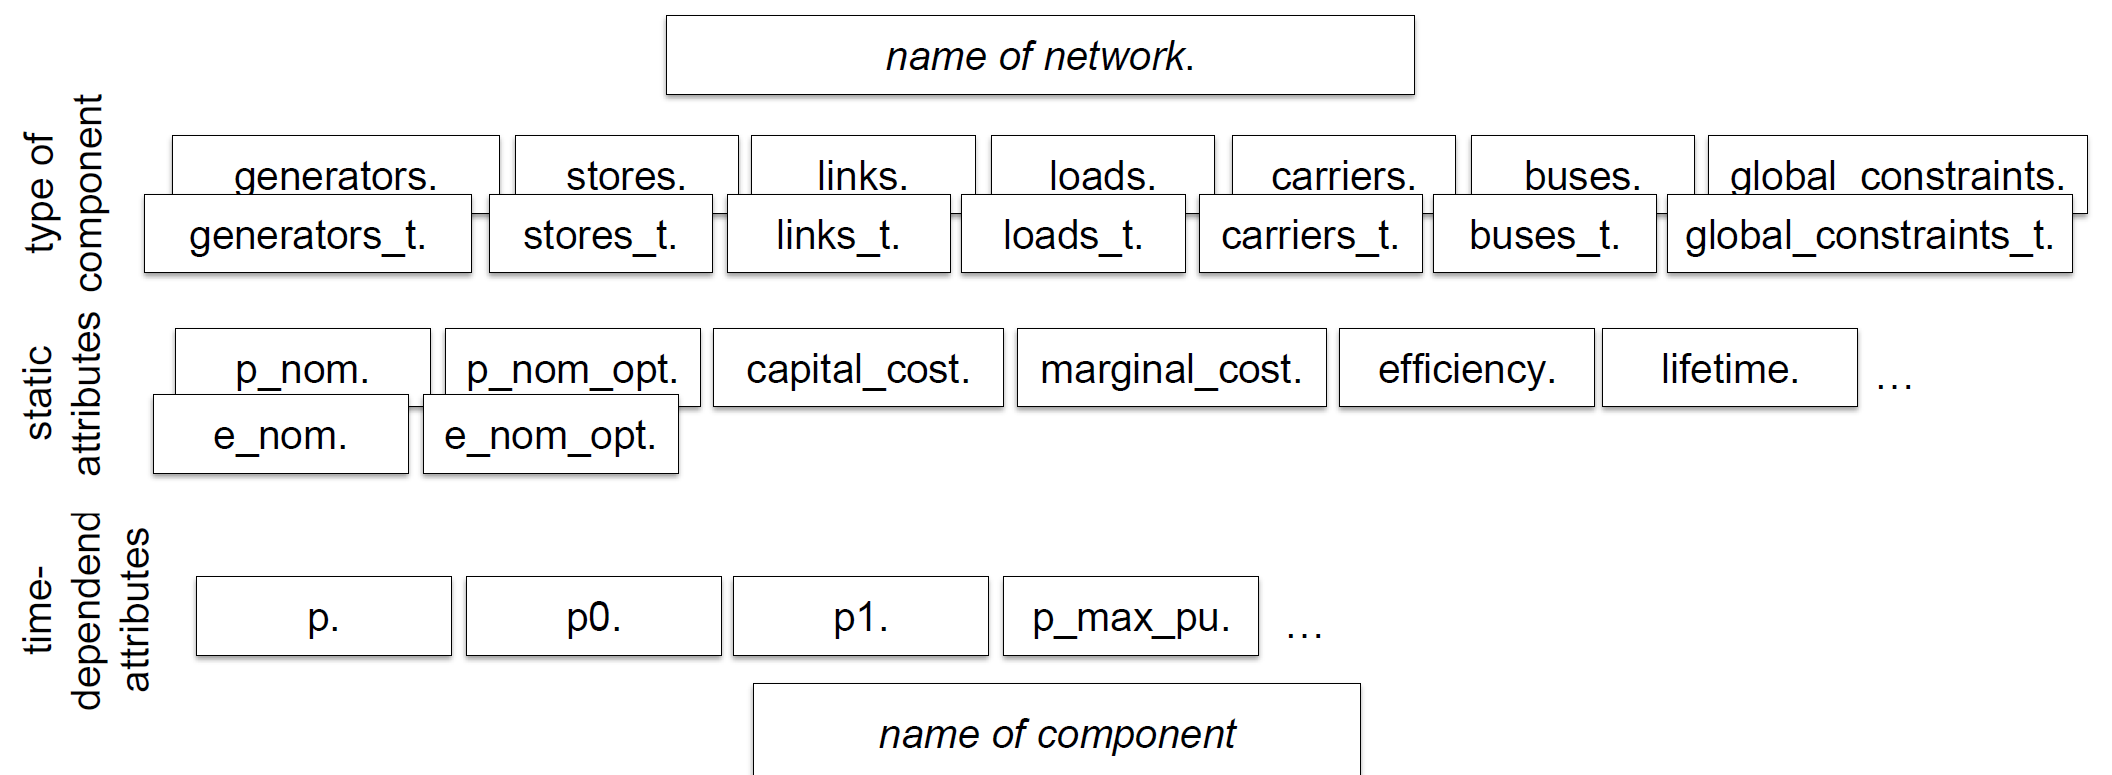